# Köppen–Geiger para o Brasil inteiro — ERA5 (1996–2025)

Extensão da análise anterior (`notebook.ipynb`, recorte parcial de GO/DF/MS/MG/SP/PR/BA/TO)
para o **território nacional completo**, usando um novo GRIB baixado do CDS com bbox
cobrindo todo o Brasil, recortado pela malha geográfica oficial do **IBGE** (não apenas
a bounding box retangular, que inclui países vizinhos e oceano).

**O algoritmo de classificação de Köppen (`koppen_classify`) é copiado sem nenhuma
alteração do notebook original** — mesma função, mesma ordem de prioridade das zonas,
mesmos 15 testes sintéticos de verificação (Seção 5). Só o dado de entrada muda.

**Diferenças em relação ao recorte parcial anterior:**
- **Área**: Brasil inteiro (bbox lat 5.25°/-33°, lon -73°/-34°), recortada pela malha do
  IBGE (API de Malhas Geográficas) para excluir Argentina, Paraguai, Bolívia, Peru,
  Colômbia, Venezuela, Guianas e oceano.
- **Resolução**: grade 0.25° (~28 km) — mais grosseira que o recorte parcial anterior
  (0.1°/~11 km). Provavelmente uma escolha prática do request original para manter o
  arquivo de tamanho gerenciável cobrindo todo o país.
- **Período**: jan/1996 a dez/2025 (30 anos; este request começa em 1996, não 1995).
- **Variáveis**: `2t` e `tp`, mesmo produto ERA5 monthly-means, mas com uma
  particularidade de metadados que exigiu um ajuste no carregamento (Seção 1).

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import earthkit.data as ekd
import geopandas as gpd
from shapely import contains_xy

GRIB_PATH = "ac6d0cca74b6679852fd5bf0178c046c.grib"
np.set_printoptions(suppress=True)


In [2]:
# Contorno dos estados brasileiros -- mesmo arquivo e mesma função do notebook original.
BR_STATES = gpd.read_file("data/brazil_states.geojson")
BR_STATES["geometry"] = BR_STATES.geometry.simplify(0.03, preserve_topology=True)


def add_state_borders(ax, color="#404040", lw=0.6, alpha=0.75):
    """Desenha o contorno suave dos estados sobre um eixo de mapa já plotado,
    preservando os limites (xlim/ylim) definidos pelos dados climáticos."""
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    BR_STATES.boundary.plot(ax=ax, color=color, linewidth=lw, alpha=alpha, zorder=5)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)


# NOVO: contorno oficial do Brasil (API de Malhas Geográficas do IBGE), usado para
# recortar a grade do ERA5 e excluir países vizinhos e oceano dentro da bbox baixada.
# Fonte: https://servicodados.ibge.gov.br/api/v3/malhas/paises/BR?formato=application/vnd.geo+json
BR_COUNTRY = gpd.read_file("data/brasil_ibge.geojson")
BR_COUNTRY_GEOM = BR_COUNTRY.union_all()


## 1. Carregar o GRIB (Brasil inteiro) e corrigir alinhamento temporal

Esse GRIB tem uma particularidade de metadados que o anterior não tinha: o campo `tp`
(precipitação) foi codificado com o tempo referenciado ao **início da previsão**
(18h do dia anterior + passo de 12h para acumular), enquanto `2t` usa o tempo de
validade direto (00h do dia 1). Isso é uma convenção normal do produto de médias
mensais do ERA5 para variáveis acumuladas (tipo `fc`, stepType `avgad`) vs.
instantâneas (tipo `an`, stepType `avgua`) — mas faz o `earthkit-data` recusar o merge
automático das duas variáveis num único `xarray.Dataset`
(`ValueError: dimensão de tempo inconsistente`).

Verificamos abaixo que a correspondência mês-a-mês entre as duas séries é 1:1 e na
mesma ordem, então carregamos cada variável separadamente e usamos o eixo de tempo já
limpo do `2t` para as duas — isso não altera nenhum valor de dado, só a *coordenada*
de tempo usada para indexar.

In [3]:
source = ekd.from_source("file", GRIB_PATH)
fieldlist = source.to_fieldlist()

idx_2t = [i for i in range(len(fieldlist)) if fieldlist[i].metadata("shortName") == "2t"]
idx_tp = [i for i in range(len(fieldlist)) if fieldlist[i].metadata("shortName") == "tp"]
print(f"Campos 2t: {len(idx_2t)}   Campos tp: {len(idx_tp)}")

ds_2t = fieldlist[idx_2t].to_xarray().rename({"forecast_reference_time": "time"})
ds_tp = fieldlist[idx_tp].to_xarray().rename({"forecast_reference_time": "time"})

# Confere a correspondencia mes-a-mes (ano, mes) antes de forcar qualquer merge
tempo_2t = pd.DatetimeIndex(ds_2t["time"].values).to_period("M")
tempo_tp = (pd.DatetimeIndex(ds_tp["time"].values) + pd.Timedelta(hours=12)).to_period("M")
assert len(tempo_2t) == len(tempo_tp), "2t e tp tem numero de passos de tempo diferente"
assert (tempo_2t == tempo_tp).all(), "2t e tp nao correspondem mes-a-mes na mesma ordem"
print("Correspondência mês-a-mês entre 2t e tp verificada: OK")

# Substitui a coordenada de tempo do tp pela do 2t (mesmos meses, mesma ordem) e mescla
ds_tp = ds_tp.assign_coords(time=ds_2t["time"].values)
ds = xr.merge([ds_2t, ds_tp])

# Unidades -- IDÊNTICO ao notebook original: 2t em Kelvin, tp em m/dia (taxa média diária)
ds["t2m_c"] = ds["2t"] - 273.15
days_in_month = ds["time"].dt.days_in_month
ds["precip_mm"] = ds["tp"] * days_in_month * 1000.0

ds["t2m_c"].attrs["units"] = "degC"
ds["precip_mm"].attrs["units"] = "mm/month"

ds


Campos 2t: 360   Campos tp: 360


Correspondência mês-a-mês entre 2t e tp verificada: OK


<xarray.Dataset> Size: 279MB
Dimensions:    (time: 360, latitude: 154, longitude: 157)
Coordinates:
  * time       (time) datetime64[us] 3kB 1996-01-01 1996-02-01 ... 2025-12-01
  * latitude   (latitude) float64 1kB 5.25 5.0 4.75 4.5 ... -32.5 -32.75 -33.0
  * longitude  (longitude) float64 1kB -73.0 -72.75 -72.5 ... -34.5 -34.25 -34.0
Data variables:
    2t         (time, latitude, longitude) float64 70MB 288.0 292.5 ... 292.3
    tp         (time, latitude, longitude) float64 70MB ...
    t2m_c      (time, latitude, longitude) float64 70MB 14.86 19.36 ... 19.16
    precip_mm  (time, latitude, longitude) float64 70MB 134.9 97.56 ... 175.0
Attributes:
    Conventions:  CF-1.8
    institution:  ECMWF

## 2. Recorte geográfico do Brasil (malha oficial do IBGE)

A bbox baixada (lat 5.25°/-33°, lon -73°/-34°) cobre boa parte da Argentina, Paraguai,
Bolívia, Peru, Colômbia, Venezuela, Guiana, Suriname e Guiana Francesa, além de oceano.
Diferente do recorte parcial anterior (onde a bbox pequena cabia quase toda dentro do
território nacional e só o oceano precisava ser mascarado), aqui é indispensável um
recorte pela fronteira real do país.

Usamos a **API de Malhas Geográficas do IBGE**
(`servicodados.ibge.gov.br/api/v3/malhas/paises/BR`) para obter o polígono oficial do
Brasil e testamos, para cada célula da grade, se o centro do pixel cai dentro do
território nacional (`shapely.contains_xy`, teste ponto-em-polígono vetorizado).

Grade total: 24178 células (154 lat × 157 lon, 0.25°)
Células dentro do Brasil (IBGE): 11326 (46.8% da bbox)
Área aproximada coberta pela máscara: 8,515,706 km²  (área oficial do Brasil, IBGE: 8.510.000 km²)


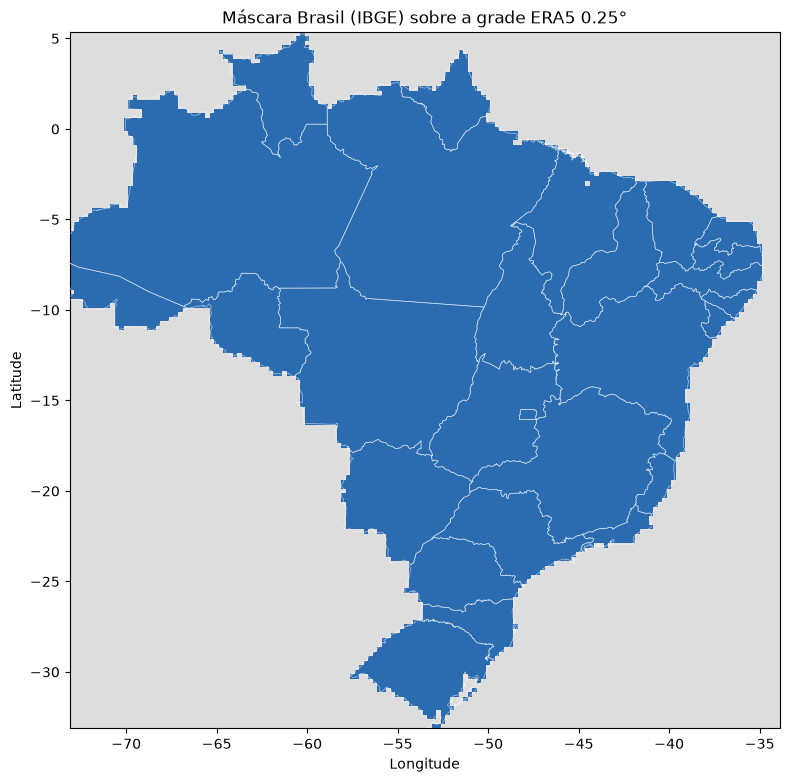

In [4]:
lats = ds["latitude"].values
lons = ds["longitude"].values
LON2D, LAT2D = np.meshgrid(lons, lats)

# Mascara Brasil: True onde o centro do pixel cai dentro do poligono oficial do IBGE
brasil_mask = contains_xy(BR_COUNTRY_GEOM, LON2D, LAT2D)

print(f"Grade total: {brasil_mask.size} células ({len(lats)} lat × {len(lons)} lon, 0.25°)")
print(f"Células dentro do Brasil (IBGE): {brasil_mask.sum()} "
      f"({100*brasil_mask.sum()/brasil_mask.size:.1f}% da bbox)")

# Conferência de sanidade: área aproximada coberta pela máscara vs. área oficial do país
R = 6371.0
dlat_km = 0.25 * (np.pi / 180) * R
area_por_lat = dlat_km * (0.25 * (np.pi / 180) * R * np.cos(np.radians(lats)))
area_total = (brasil_mask * area_por_lat[:, None]).sum()
print(f"Área aproximada coberta pela máscara: {area_total:,.0f} km²  "
      f"(área oficial do Brasil, IBGE: 8.510.000 km²)")

fig, ax = plt.subplots(figsize=(8, 8))
ax.pcolormesh(lons, lats, brasil_mask, cmap=ListedColormap(["#dddddd", "#2b6cb0"]), shading="auto")
add_state_borders(ax, color="white", lw=0.5, alpha=0.6)
ax.set_title("Máscara Brasil (IBGE) sobre a grade ERA5 0.25°")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


## 3. Análise exploratória (Brasil inteiro)

Mesma estrutura da Seção 2 do notebook original (série temporal + tendência anual),
agora com a média espacial restrita às células dentro do território brasileiro
(`brasil_mask`), não à bbox inteira.

**Nota técnica:** ao mascarar com `.where(brasil_mask)`, células fora do Brasil ficam
com `NaN` em todos os meses. Para a soma anual de precipitação isso importa: o `xarray`
(como o `numpy`) retorna `0.0`, não `NaN`, para a soma de uma fatia inteiramente `NaN`
— se não tratado, isso puxaria a média espacial pra baixo com zeros espúrios de fora do
país. Usamos `min_count=1` nos `.sum()` para forçar `NaN` nesse caso.

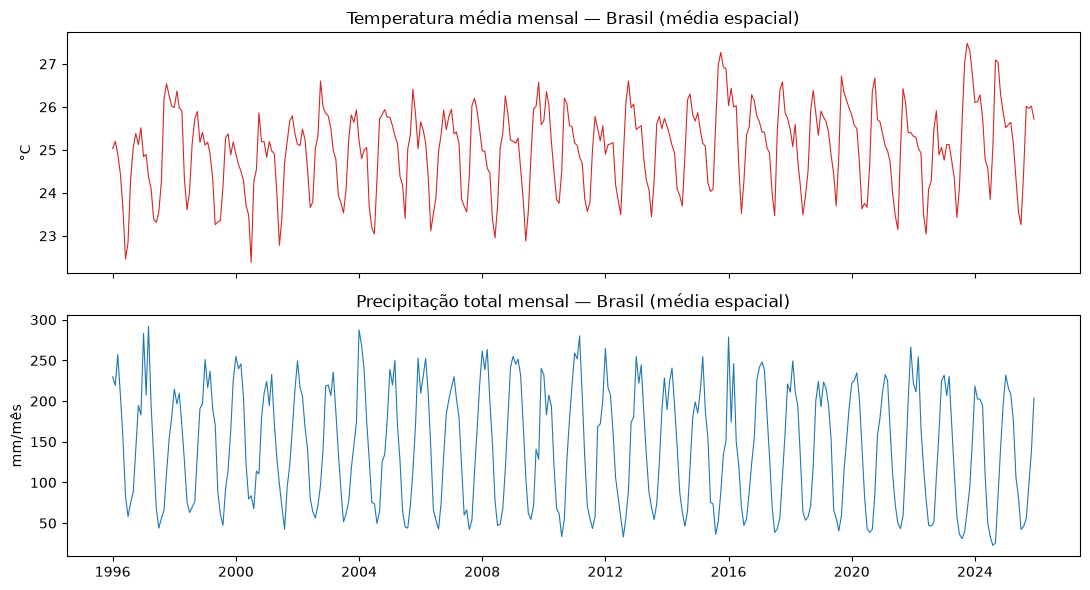

In [5]:
brasil_da = xr.DataArray(brasil_mask, dims=["latitude", "longitude"],
                          coords={"latitude": ds.latitude, "longitude": ds.longitude})

t2m_masked = ds["t2m_c"].where(brasil_da)
precip_masked = ds["precip_mm"].where(brasil_da)

regional_t = t2m_masked.mean(dim=["latitude", "longitude"])
regional_p = precip_masked.mean(dim=["latitude", "longitude"])

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
regional_t.plot(ax=axes[0], color="tab:red", lw=0.8)
axes[0].set_title("Temperatura média mensal — Brasil (média espacial)")
axes[0].set_ylabel("°C")
axes[0].set_xlabel("")

regional_p.plot(ax=axes[1], color="tab:blue", lw=0.8)
axes[1].set_title("Precipitação total mensal — Brasil (média espacial)")
axes[1].set_ylabel("mm/mês")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()


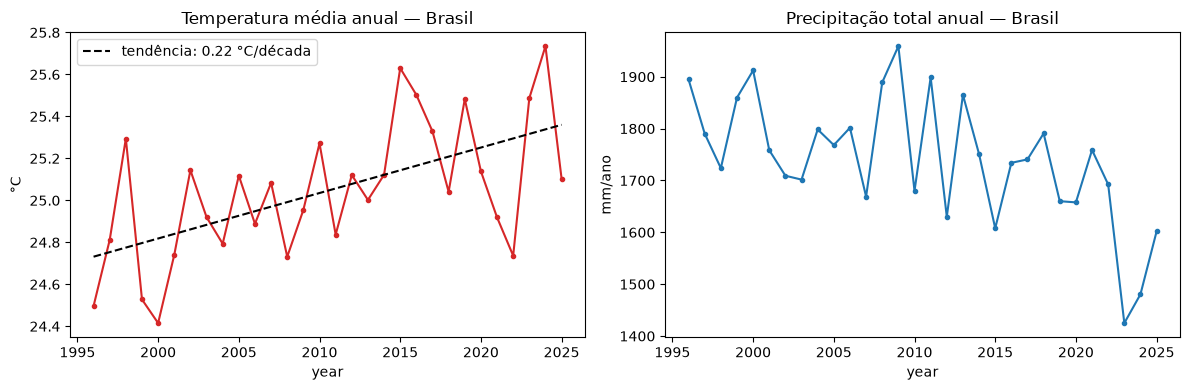

In [6]:
annual_t = t2m_masked.groupby("time.year").mean(dim=["time", "latitude", "longitude"])
annual_p_percell = precip_masked.groupby("time.year").sum(dim="time", min_count=1)
annual_p = annual_p_percell.mean(dim=["latitude", "longitude"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
annual_t.plot(ax=axes[0], marker="o", ms=3, color="tab:red")
z = np.polyfit(annual_t["year"], annual_t.values, 1)
axes[0].plot(annual_t["year"], np.polyval(z, annual_t["year"]), "k--",
             label=f"tendência: {z[0]*10:.2f} °C/década")
axes[0].set_title("Temperatura média anual — Brasil")
axes[0].set_ylabel("°C")
axes[0].legend()

annual_p.plot(ax=axes[1], marker="o", ms=3, color="tab:blue")
axes[1].set_title("Precipitação total anual — Brasil")
axes[1].set_ylabel("mm/ano")

plt.tight_layout()
plt.show()


## 4. Climatologia mensal (1996–2025)

Igual à Seção 3 do notebook original: para cada célula e cada mês-calendário,
calculamos a média dos 30 anos. É essa climatologia que alimenta as regras de Köppen.

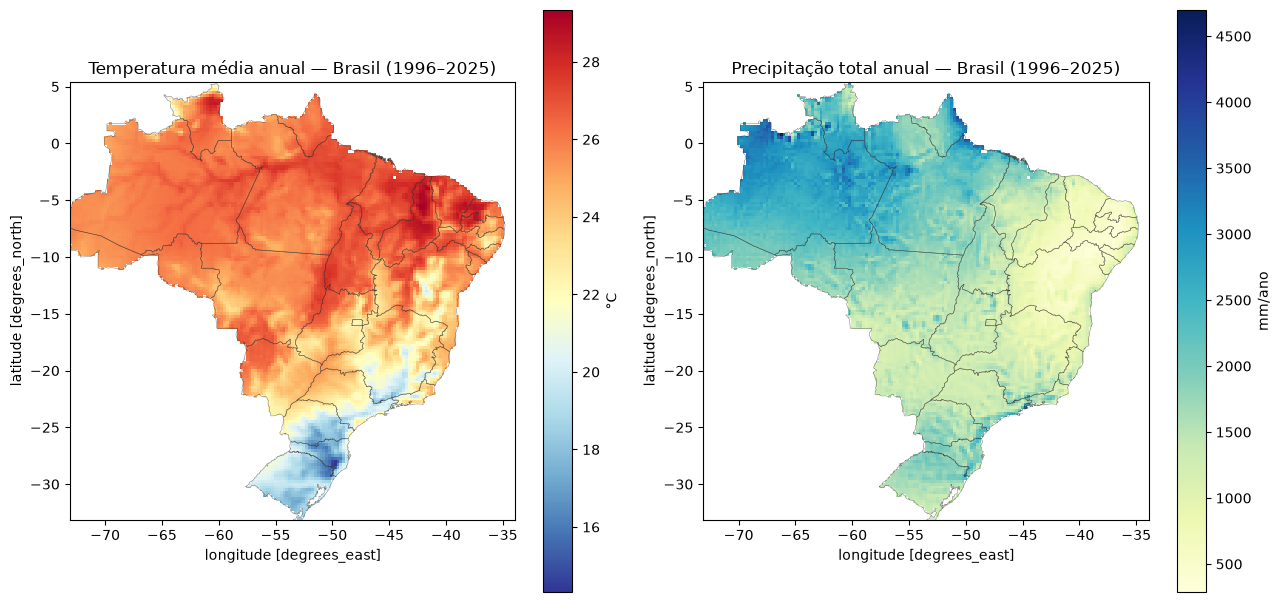

In [7]:
t_clim = t2m_masked.groupby("time.month").mean(dim="time").sortby("month")
p_clim = precip_masked.groupby("time.month").mean(dim="time").sortby("month")

mat_map = t_clim.mean(dim="month")
map_map = p_clim.sum(dim="month", min_count=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 10))
mat_map.plot(ax=axes[0], cmap="RdYlBu_r", cbar_kwargs={"label": "°C", "shrink": 0.6})
axes[0].set_title("Temperatura média anual — Brasil (1996–2025)")
add_state_borders(axes[0], color="#333333", lw=0.4, alpha=0.6)
axes[0].set_aspect("equal")

map_map.plot(ax=axes[1], cmap="YlGnBu", cbar_kwargs={"label": "mm/ano", "shrink": 0.6})
axes[1].set_title("Precipitação total anual — Brasil (1996–2025)")
add_state_borders(axes[1], color="#333333", lw=0.4, alpha=0.6)
axes[1].set_aspect("equal")

plt.tight_layout()
plt.show()


## 5. Algoritmo de classificação de Köppen–Geiger

**Função copiada, caractere por caractere, do notebook original** (`notebook.ipynb`,
célula `e6eb2e4e`) — mesma lógica, mesma ordem de prioridade B→A→E→C/D, sem nenhuma
alteração. Logo abaixo, a mesma bateria de 15 testes sintéticos do notebook original
(também copiada sem alteração) é reexecutada aqui para comprovar que o algoritmo
segue idêntico.

In [8]:
def koppen_classify(T, P, summer_idx=(9, 10, 11, 0, 1, 2), winter_idx=(3, 4, 5, 6, 7, 8)):
    """
    T, P: arrays (12, lat, lon) com climatologia mensal de temperatura (°C) e
          precipitacao (mm/mes), mes 0 = Janeiro ... mes 11 = Dezembro.
    summer_idx / winter_idx: indices de mes (0-based) do semestre de verao e inverno
          para o hemisferio da regiao (default: hemisferio sul).
    Retorna: array 2D de strings com o codigo Koppen (ex: 'Aw', 'Cfa', 'BSh', ...).
             Celulas sem dado valido (oceano/mascara) recebem 'NA'.
    """
    T = np.asarray(T)
    P = np.asarray(P)

    # celulas com qualquer mes faltante (ex: oceano dentro da bbox) ficam de fora
    valid = ~(np.isnan(T).any(axis=0) | np.isnan(P).any(axis=0))

    MAT = T.mean(axis=0)
    MAP = P.sum(axis=0)
    Tcold = T.min(axis=0)
    Thot = T.max(axis=0)
    Pdry = P.min(axis=0)
    TM10 = (T > 10).sum(axis=0)

    Psum = P[list(summer_idx)]
    Pwin = P[list(winter_idx)]
    Psdry, Pswet = Psum.min(axis=0), Psum.max(axis=0)
    Pwdry, Pwwet = Pwin.min(axis=0), Pwin.max(axis=0)

    frac_win = Pwin.sum(axis=0) / MAP
    frac_sum = Psum.sum(axis=0) / MAP
    Pthresh = np.where(frac_win >= 0.7, 2 * MAT,
                        np.where(frac_sum >= 0.7, 2 * MAT + 28, 2 * MAT + 14))

    code = np.full(MAT.shape, "NA", dtype="<U3")
    unresolved = valid.copy()

    # --- B: clima arido (checado primeiro, tem prioridade sobre A/C/D) ---
    is_B = unresolved & (MAP < 10 * Pthresh)
    is_h = MAT >= 18
    is_arid = is_B & (MAP < 5 * Pthresh)
    is_semiarid = is_B & ~is_arid
    code[is_arid & is_h] = "BWh"
    code[is_arid & ~is_h] = "BWk"
    code[is_semiarid & is_h] = "BSh"
    code[is_semiarid & ~is_h] = "BSk"
    unresolved &= ~is_B

    # --- A: clima tropical ---
    is_A = unresolved & (Tcold >= 18)
    is_Af = is_A & (Pdry >= 60)
    is_Am = is_A & ~is_Af & (Pdry >= (100 - MAP / 25))
    is_Aws = is_A & ~is_Af & ~is_Am
    dry_month = np.argmin(P, axis=0)
    dry_in_summer = np.isin(dry_month, list(summer_idx))
    is_As = is_Aws & dry_in_summer
    is_Aw = is_Aws & ~dry_in_summer
    code[is_Af] = "Af"
    code[is_Am] = "Am"
    code[is_As] = "As"
    code[is_Aw] = "Aw"
    unresolved &= ~is_A

    # --- E: clima polar ---
    is_E = unresolved & (Thot < 10)
    code[is_E & (Thot >= 0)] = "ET"
    code[is_E & (Thot < 0)] = "EF"
    unresolved &= ~is_E

    # --- C / D: temperado / continental ---
    is_CD = unresolved
    is_D = is_CD & (Tcold < -3)
    is_C = is_CD & ~is_D

    is_f = is_CD & (Pdry > 40)
    is_w = is_CD & ~is_f & (Pswet >= 10 * Pwdry)
    is_s = is_CD & ~is_f & ~is_w & (Pwwet >= 3 * Psdry)
    # fallback: quando nao se enquadra perfeitamente em w/s mas Pdry<=40, classifica como f
    # (evita celulas sem classificacao por empates nas condicoes de fronteira)
    is_unclassified_rain = is_CD & ~is_f & ~is_w & ~is_s
    is_f = is_f | is_unclassified_rain

    is_a = is_CD & (Thot >= 22)
    is_b = is_CD & (Thot < 22) & (TM10 >= 4)
    is_c = is_CD & (Thot < 22) & (TM10 < 4) & (Tcold >= -38)
    is_d = is_CD & (Tcold < -38)

    for zone_mask, zone_letter in [(is_C, "C"), (is_D, "D")]:
        for rain_mask, rain_letter in [(is_f, "f"), (is_w, "w"), (is_s, "s")]:
            m = zone_mask & rain_mask
            code[m & is_a] = zone_letter + rain_letter + "a"
            code[m & is_b] = zone_letter + rain_letter + "b"
            code[m & is_c] = zone_letter + rain_letter + "c"
            if zone_letter == "D":
                code[m & is_d] = zone_letter + rain_letter + "d"

    assert (code[~valid] == "NA").all()
    assert (code[valid] != "NA").all(), "existem celulas com dado valido que nao foram classificadas"
    return code, valid


In [9]:
def _classify_profile(T12, P12):
    """Classifica um unico perfil mensal (listas de 12 valores)."""
    T = np.array(T12, dtype=float).reshape(12, 1, 1)
    P = np.array(P12, dtype=float).reshape(12, 1, 1)
    return koppen_classify(T, P)[0][0, 0]


# Perfis sinteticos (hemisferio sul: verao = out-mar, inverno = abr-set).
# Jan .......................................................... Dez
CASOS_TESTE = {
    "Af":  ([27] * 12,
            [280, 280, 300, 300, 300, 160, 120, 80, 100, 140, 180, 220]),
    "Am":  ([27] * 12,
            [300, 350, 400, 400, 380, 250, 130, 40, 15, 30, 80, 150]),
    "Aw":  ([26] * 12,
            [280, 260, 270, 150, 40, 2, 1, 5, 40, 180, 230, 250]),
    "As":  ([26] * 12,          # seca no verao (set-dez), chuva no inverno
            [60, 90, 150, 200, 250, 280, 220, 110, 30, 20, 25, 40]),
    "BSh": ([26] * 12,
            [80, 110, 130, 60, 20, 5, 2, 1, 2, 10, 30, 60]),
    "BWh": ([28] * 12,
            [5, 5, 3, 2, 1, 0, 0, 0, 1, 2, 3, 5]),
    "Cfa": ([24, 24, 22, 19, 16, 13, 13, 14, 16, 19, 21, 23],
            [120, 130, 130, 140, 120, 140, 130, 140, 140, 120, 110, 120]),
    "Cfb": ([20.5, 20, 19, 17, 14, 13, 13, 14, 15, 17, 18, 20],
            [170, 150, 130, 90, 100, 110, 100, 80, 120, 140, 120, 150]),
    "Cwa": ([23.5, 23.5, 23, 21, 19, 17.5, 17.5, 19, 21, 22, 23, 23],
            [280, 200, 160, 60, 40, 20, 15, 20, 50, 130, 180, 260]),
    "Cwb": ([21.5, 21.5, 21, 20, 18, 16.5, 15.5, 17, 19, 20, 21, 21],
            [300, 180, 150, 60, 25, 12, 10, 12, 35, 120, 220, 300]),
    "Cwc": ([11.5, 11, 9.5, 8, 6, 4.5, 4.5, 6, 8, 9.5, 10, 11],   # so 3 meses > 10 C
            [200, 160, 150, 60, 40, 20, 15, 25, 60, 140, 180, 210]),
    "Csa": ([22.7, 22.5, 22, 21, 19, 18, 17.5, 17.9, 19, 20.5, 22, 22.7],
            [40, 60, 80, 120, 140, 130, 100, 50, 25, 20, 20, 25]),
    "Csb": ([21.5, 21.3, 21, 20, 19, 17.5, 17, 17.5, 18.5, 19.5, 20.5, 21.5],
            [40, 60, 80, 120, 140, 130, 100, 50, 25, 20, 20, 25]),
    "ET":  ([5, 5, 4, 2, 0, -2, -3, -1, 1, 3, 4, 5], [50] * 12),
    "EF":  ([-5] * 12, [30] * 12),
}

falhas = []
for esperado, (T12, P12) in CASOS_TESTE.items():
    obtido = _classify_profile(T12, P12)
    if obtido != esperado:
        falhas.append((esperado, obtido))
    print(f"{'OK   ' if obtido == esperado else 'FALHA'} esperado={esperado:<4} obtido={obtido:<4}"
          f"  Tcold={min(T12):5.1f}  Thot={max(T12):5.1f}  MAP={sum(P12):5.0f}mm  Pdry={min(P12):3.0f}mm")

assert not falhas, f"casos que falharam: {falhas}"
print(f"\n{len(CASOS_TESTE)}/{len(CASOS_TESTE)} casos corretos -- algoritmo idêntico ao notebook original")


OK    esperado=Af   obtido=Af    Tcold= 27.0  Thot= 27.0  MAP= 2460mm  Pdry= 80mm
OK    esperado=Am   obtido=Am    Tcold= 27.0  Thot= 27.0  MAP= 2525mm  Pdry= 15mm
OK    esperado=Aw   obtido=Aw    Tcold= 26.0  Thot= 26.0  MAP= 1708mm  Pdry=  1mm
OK    esperado=As   obtido=As    Tcold= 26.0  Thot= 26.0  MAP= 1475mm  Pdry= 20mm
OK    esperado=BSh  obtido=BSh   Tcold= 26.0  Thot= 26.0  MAP=  510mm  Pdry=  1mm
OK    esperado=BWh  obtido=BWh   Tcold= 28.0  Thot= 28.0  MAP=   27mm  Pdry=  0mm
OK    esperado=Cfa  obtido=Cfa   Tcold= 13.0  Thot= 24.0  MAP= 1540mm  Pdry=110mm
OK    esperado=Cfb  obtido=Cfb   Tcold= 13.0  Thot= 20.5  MAP= 1460mm  Pdry= 80mm
OK    esperado=Cwa  obtido=Cwa   Tcold= 17.5  Thot= 23.5  MAP= 1415mm  Pdry= 15mm
OK    esperado=Cwb  obtido=Cwb   Tcold= 15.5  Thot= 21.5  MAP= 1424mm  Pdry= 10mm
OK    esperado=Cwc  obtido=Cwc   Tcold=  4.5  Thot= 11.5  MAP= 1260mm  Pdry= 15mm
OK    esperado=Csa  obtido=Csa   Tcold= 17.5  Thot= 22.7  MAP=  810mm  Pdry= 20mm
OK    esperado=C

## 6. Aplicar a classificação ao Brasil inteiro

Como `t_clim`/`p_clim` (Seção 4) já foram calculadas a partir de `t2m_masked`/
`precip_masked` — que por sua vez já aplicaram `.where(brasil_da)` lá na Seção 3 —,
as células fora do Brasil (países vizinhos, oceano) já chegam como `NaN` na entrada do
`koppen_classify`. Por isso `valid_mask` (que só verifica ausência de `NaN`) já acaba
coincidindo exatamente com `brasil_mask` neste pipeline (conferido abaixo: 11.326 =
11.326, zero células de país vizinho sobrando) — o mascaramento pelo IBGE efetivamente
aconteceu "rio acima", na Seção 3.

Mesmo assim, calculamos `territorio_mask = valid_mask & brasil_mask` explicitamente
abaixo: é redundante *neste* notebook, mas deixa a intenção clara e protege contra
erro caso a função seja reaproveitada depois com uma climatologia que não tenha
passado pelo mascaramento prévio.

In [10]:
T_arr = t_clim.transpose("month", "latitude", "longitude").values
P_arr = p_clim.transpose("month", "latitude", "longitude").values
koppen_codes, valid_mask = koppen_classify(T_arr, P_arr)

# territorio_mask = dado valido (nao-oceano) E dentro do poligono do Brasil (IBGE)
territorio_mask = valid_mask & brasil_mask

print(f"Células com dado ERA5 válido (terra, sem distinguir país): {valid_mask.sum()}")
print(f"Células dentro do território brasileiro (IBGE):            {brasil_mask.sum()}")
print(f"Células classificadas (interseção -- Brasil + dado válido): {territorio_mask.sum()}")
print(f"Células excluídas por serem de países vizinhos:             "
      f"{(valid_mask & ~brasil_mask).sum()}")

unique, counts = np.unique(koppen_codes[territorio_mask], return_counts=True)
tabela_koppen = pd.DataFrame({"climate": unique, "n_pixels": counts,
                               "%": 100 * counts / counts.sum()}).sort_values("%", ascending=False)
tabela_koppen


Células com dado ERA5 válido (terra, sem distinguir país): 11326
Células dentro do território brasileiro (IBGE):            11326
Células classificadas (interseção -- Brasil + dado válido): 11326
Células excluídas por serem de países vizinhos:             0


,climate,n_pixels,%
3,Aw,5249,46.344694
0,Af,1976,17.446583
1,Am,1955,17.261169
4,BSh,901,7.955147
6,Cfa,702,6.198128
7,Cfb,205,1.809995
2,As,139,1.227265
8,Cwa,132,1.165460
9,Cwb,38,0.335511
5,BWh,29,0.256048


## 7. Mapa de classificação de Köppen — Brasil inteiro

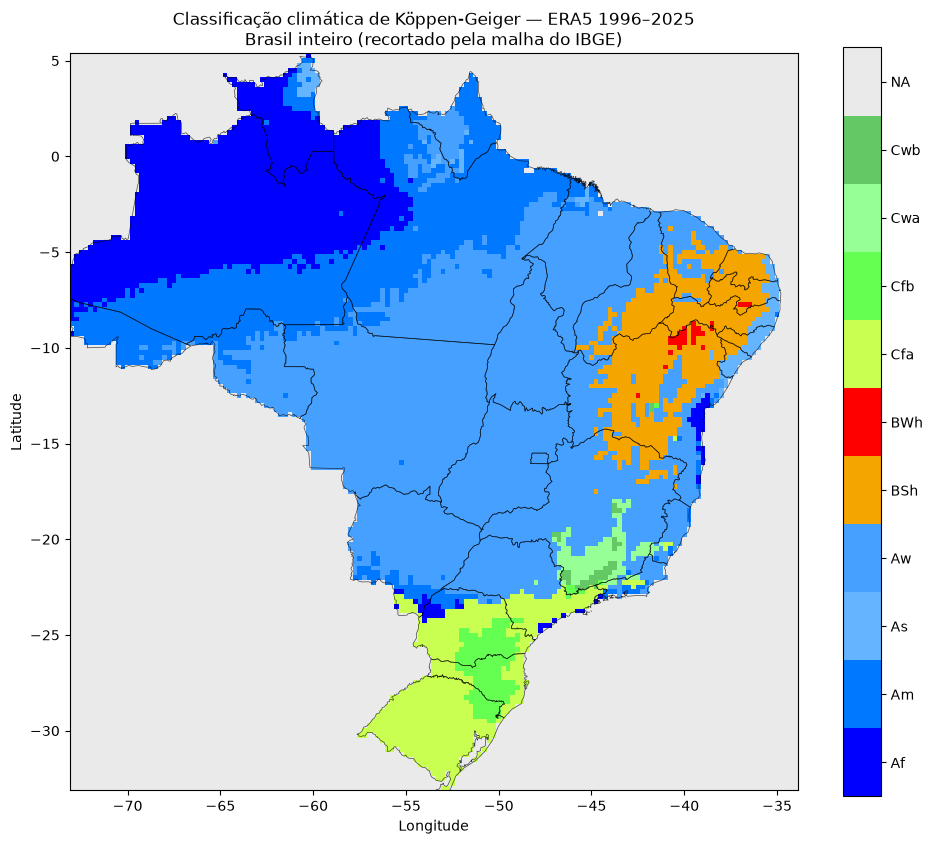

In [11]:
# Paleta no padrão Köppen-Geiger -- mesmo dicionário do notebook original (Peel et al. 2007).
# NA = oceano ou fora do território brasileiro (países vizinhos).
KOPPEN_COLORS = {
    "Af": "#0000FF", "Am": "#0078FF", "Aw": "#46A0FF", "As": "#64B4FF",
    "BWh": "#FF0000", "BWk": "#FFA0A0", "BSh": "#F5A500", "BSk": "#FFDC64",
    "Csa": "#FFFF00", "Csb": "#C8C800", "Csc": "#969600",
    "Cwa": "#96FF96", "Cwb": "#64C864", "Cwc": "#329632",
    "Cfa": "#C8FF50", "Cfb": "#64FF50", "Cfc": "#32C800",
    "Dsa": "#FF00FF", "Dsb": "#C800C8", "Dsc": "#963296", "Dsd": "#966496",
    "Dwa": "#ABB1FF", "Dwb": "#5A77DB", "Dwc": "#4C51B5", "Dwd": "#320087",
    "Dfa": "#00FFFF", "Dfb": "#37C8FF", "Dfc": "#007D7D", "Dfd": "#00465F",
    "ET": "#B3B3B3", "EF": "#696969",
    "NA": "#EAEAEA",
}

# Fora do territorio (oceano ou pais vizinho) vira "NA" explicitamente para o mapa
codes_brasil = np.where(territorio_mask, koppen_codes, "NA")

codes_present = sorted(np.unique(codes_brasil))
cmap = ListedColormap([KOPPEN_COLORS.get(c, "#FF00FF") for c in codes_present])
code_to_int = {c: i for i, c in enumerate(codes_present)}
int_grid = np.vectorize(code_to_int.get)(codes_brasil)

fig, ax = plt.subplots(figsize=(10, 11))
im = ax.pcolormesh(
    lons, lats, int_grid,
    cmap=cmap, vmin=-0.5, vmax=len(codes_present) - 0.5, shading="auto",
)
ax.set_title("Classificação climática de Köppen-Geiger — ERA5 1996–2025\nBrasil inteiro (recortado pela malha do IBGE)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
add_state_borders(ax, color="black", lw=0.5, alpha=0.7)

cbar = fig.colorbar(im, ax=ax, ticks=range(len(codes_present)), shrink=0.7)
cbar.ax.set_yticklabels(codes_present)

plt.tight_layout()
plt.show()


## 8. Comparação com as proporções nacionais do artigo (zonas A/B/C)

O artigo (Alvares et al. 2013) reporta, para o Brasil inteiro: **A = 81,4%, B = 4,9%,
C = 13,7%** (sem D nem E). Com o recorte parcial anterior não dava pra comparar essas
proporções nacionais diretamente — agora, cobrindo o país inteiro, dá.

In [12]:
zonas_validas = np.array([c[0] for c in codes_brasil[territorio_mask]])  # 1ª letra = zona

unique_z, counts_z = np.unique(zonas_validas, return_counts=True)
tabela_zonas = pd.DataFrame({"zona": unique_z, "% ERA5 (este notebook)": 100 * counts_z / counts_z.sum()})
tabela_zonas = tabela_zonas.set_index("zona")

artigo = pd.Series({"A": 81.4, "B": 4.9, "C": 13.7}, name="% artigo (Alvares et al. 2013)")
comparacao = tabela_zonas.join(artigo, how="outer").fillna(0).round(1)
comparacao


,% ERA5 (este notebook),% artigo (Alvares et al. 2013)
zona,,
A,82.3,81.4
B,8.2,4.9
C,9.5,13.7


## 9. Ressalvas específicas desta análise (Brasil inteiro)

O algoritmo é idêntico e passa nos mesmos 15/15 testes sintéticos do notebook
original (Seção 5) — as ressalvas abaixo são sobre os **dados de entrada**, que mudaram
em vários aspectos em relação ao recorte parcial:

- **Resolução mais grosseira**: 0,25° (~28 km) aqui vs. 0,1° (~11 km) no recorte
  parcial. Isso significa que efeitos de relevo local (picos isolados, vales estreitos)
  ficam ainda menos resolvidos do que já estavam antes — o clima Cwc do artigo (só 3
  sítios no Brasil, todos em picos) tem ainda menos chance de aparecer nesta grade.
- **Período diferente**: 1996–2025 (30 anos) aqui vs. 1995–2025 (31 anos) no recorte
  parcial. Isso não deveria mudar a climatologia de forma perceptível (só um ano a
  menos), mas é bom deixar registrado para quem for comparar os dois notebooks lado a
  lado.
- **Viés seco do ERA5**: o mesmo viés já documentado no notebook original (ERA5
  subestimando precipitação em ~12–38% nas localidades de referência testadas) se
  aplica aqui também, e provavelmente explica parte de qualquer excesso de área B
  (árido/semiárido) em relação ao artigo.
- **Precisão da máscara do IBGE**: a malha usada tem qualidade "intermediária" (não a
  de máxima resolução), suficiente para uma grade de 0,25° mas que pode arredondar
  ligeiramente a fronteira em trechos de litoral recortado ou rios de fronteira. Ilhas
  pequenas (Fernando de Noronha, Trindade etc.) não aparecem no mapa por serem menores
  que um pixel de 0,25° — mesma limitação de qualquer grade regular nessa resolução.
- **Comparação de zonas (Seção 8)**: as proporções nacionais A/B/C do ERA5 podem
  divergir das do artigo tanto por viés de dados quanto por mudança climática real
  entre as linhas de base (1950–1990 no artigo vs. 1996–2025 aqui) — este notebook não
  tenta separar as duas causas, só reporta a comparação.